#**Applied AI - Final Project**

## Title: Intelligent Business Document Processing Using NLP

### Project Objective -
Design and evaluate an AI-assisted system that classifies business documents and retrieves relevant information using Natural Language Processing.

### Techniques -
- TF-IDF and text classification
- Logistic Regression and Linear SVM
- BM25 and semantic retrieval
- Model evaluation and statistical comparison
- A/B testing methodology

### Project Scope -
This notebook implements and evaluates document classification and retrieval components. Other system components, including access control and human review, are addressed in the proposed architecture.


##Step 2 - Install the required libraries
- These packages will support realistic sample-data generation, keyword retrieval, and semantic embeddings

In [1]:
!pip -q install faker rank-bm25 sentence-transformers

##Step 3 - Generate our business document dataset

In [2]:
import pandas as pd
import numpy as np
import random
from faker import Faker

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
fake = Faker()
Faker.seed(SEED)

# Four document categories
categories = [
    "Invoice",
    "Purchase Order",
    "Shipping Notice",
    "Service Report"
]

# Different writing styles for each category
templates = {
    "Invoice": [
        "Invoice {doc_id} issued to {company} on {date}. "
        "Payment of ${amount} is due within {days} days.",

        "Billing statement {doc_id} for {company}. "
        "Total outstanding balance: ${amount}. "
        "Payment deadline is {date}.",

        "Account {company} received invoice reference {doc_id}. "
        "Amount payable is ${amount} for services provided."
    ],

    "Purchase Order": [
        "Purchase order {doc_id} submitted by {company} on {date}. "
        "Requested quantity is {quantity} units.",

        "Procurement request {doc_id}: {company} ordered "
        "{quantity} units with an estimated value of ${amount}.",

        "Order authorization {doc_id} confirms the purchase of "
        "{quantity} items for {company}."
    ],

    "Shipping Notice": [
        "Shipment {doc_id} for {company} was dispatched on {date}. "
        "Estimated delivery is within {days} days.",

        "Delivery notification {doc_id}: {quantity} units "
        "are in transit to {company}.",

        "Logistics update {doc_id}: delivery for {company} "
        "was postponed because inventory was unavailable."
    ],

    "Service Report": [
        "Service report {doc_id} for {company} dated {date}. "
        "Technician completed routine equipment inspection.",

        "Maintenance record {doc_id}: equipment at {company} "
        "required repair and performance testing.",

        "Technical service summary {doc_id} confirms "
        "inspection and replacement of faulty components."
    ]
}

records = []

for category in categories:
    for i in range(50):
        data = {
            "doc_id": fake.bothify(text="DOC-#####"),
            "company": fake.company(),
            "date": str(fake.date_this_year()),
            "amount": round(random.uniform(100, 10000), 2),
            "days": random.randint(5, 45),
            "quantity": random.randint(1, 500)
        }

        # Reserve one template per class for unseen-template testing
        template_id = i % 3
        text = templates[category][template_id].format(**data)

        records.append({
            "document_id": f"DOC-{len(records)+1:04d}",
            "category": category,
            "text": text,
            "template_id": template_id
        })

df = pd.DataFrame(records)

print("Dataset shape:", df.shape)
print("\nDocuments per category:")
print(df["category"].value_counts())

display(df.head(8))

Dataset shape: (200, 4)

Documents per category:
category
Invoice            50
Purchase Order     50
Shipping Notice    50
Service Report     50
Name: count, dtype: int64


,document_id,category,text,template_id
0,DOC-0001,Invoice,Invoice DOC-10433 issued to Doyle Ltd on 2026-...,0
1,DOC-0002,Invoice,Billing statement DOC-81960 for Davis and Sons...,1
2,DOC-0003,Invoice,Account Cole LLC received invoice reference DO...,2
3,DOC-0004,Invoice,Invoice DOC-02654 issued to Lewis LLC on 2026-...,0
4,DOC-0005,Invoice,Billing statement DOC-61559 for Roman-Blair. T...,1
5,DOC-0006,Invoice,Account Ray-Bush received invoice reference DO...,2
6,DOC-0007,Invoice,Invoice DOC-34131 issued to Ramirez-Reid on 20...,0
7,DOC-0008,Invoice,"Billing statement DOC-55341 for Reid, Ferguson...",1


##Check dataset quality

In [3]:
# Check missing values and duplicates
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate documents:", df["text"].duplicated().sum())

# Examine document length
df["word_count"] = df["text"].str.split().str.len()

print("\nDocument length statistics:")
display(df.groupby("category")["word_count"].describe().round(2))

# Check template distribution
print("\nTemplate distribution:")
display(pd.crosstab(df["category"], df["template_id"]))

Missing values:
document_id    0
category       0
text           0
template_id    0
dtype: int64

Duplicate documents: 0

Document length statistics:


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
Invoice,50.0,15.20,1.53,13.0,14.0,15.0,16.0,18.0
Purchase Order,50.0,13.78,1.47,11.0,13.0,14.0,14.0,16.0
Service Report,50.0,12.52,1.59,11.0,11.0,12.0,14.0,15.0
Shipping Notice,50.0,13.48,2.01,10.0,12.0,13.5,15.0,17.0



Template distribution:


template_id,0,1,2
category,,,
Invoice,17,17,16
Purchase Order,17,17,16
Service Report,17,17,16
Shipping Notice,17,17,16


## Step 4 - Exploratory Data Analysis (EDA)

This section examines category balance and document-length
distributions before NLP model development.

The analysis helps identify potential dataset biases,
including differences in document length across categories.


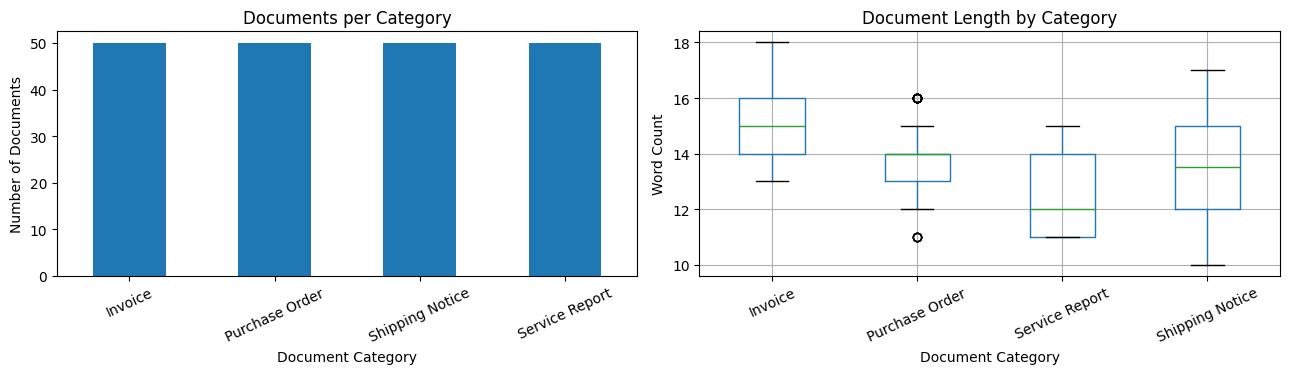

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Document distribution
df["category"].value_counts().plot(
    kind="bar",
    ax=axes[0]
)
axes[0].set_title("Documents per Category")
axes[0].set_xlabel("Document Category")
axes[0].set_ylabel("Number of Documents")
axes[0].tick_params(axis="x", rotation=25)

# Document length distribution
df.boxplot(
    column="word_count",
    by="category",
    ax=axes[1]
)
axes[1].set_title("Document Length by Category")
axes[1].set_xlabel("Document Category")
axes[1].set_ylabel("Word Count")
axes[1].tick_params(axis="x", rotation=25)

plt.suptitle("")
plt.tight_layout()
plt.show()

## What results tell -
- Category distribution: All four categories contain 50 documents each, so our dataset is balanced.

- Document length: Invoices generally contain more words than service reports. This suggests that document length might influence classification.

- Dataset limitation: Our documents are short and generated using only three templates per category. We need to investigate whether our models learn meaningful language patterns or simply recognize template wording.

##Step 5 - NLP Model Development: TF-IDF + Logistic Regression

This experiment evaluates whether a machine learning model can
classify business documents based on their textual content.

To reduce template leakage, documents generated using templates
0 and 1 are used for training, while documents generated using
template 2 are reserved for testing.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Split dataset by template rather than randomly
train_df = df[df["template_id"].isin([0, 1])].copy()
test_df = df[df["template_id"] == 2].copy()

X_train = train_df["text"]
y_train = train_df["category"]

X_test = test_df["text"]
y_test = test_df["category"]

print("Training documents:", len(train_df))
print("Testing documents:", len(test_df))

print("\nTraining category distribution:")
print(y_train.value_counts())

print("\nTesting category distribution:")
print(y_test.value_counts())

Training documents: 136
Testing documents: 64

Training category distribution:
category
Invoice            34
Purchase Order     34
Shipping Notice    34
Service Report     34
Name: count, dtype: int64

Testing category distribution:
category
Invoice            16
Purchase Order     16
Shipping Notice    16
Service Report     16
Name: count, dtype: int64


Logistic Regression Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

        Invoice       1.00      1.00      1.00        16
 Purchase Order       1.00      1.00      1.00        16
 Service Report       1.00      1.00      1.00        16
Shipping Notice       1.00      1.00      1.00        16

       accuracy                           1.00        64
      macro avg       1.00      1.00      1.00        64
   weighted avg       1.00      1.00      1.00        64



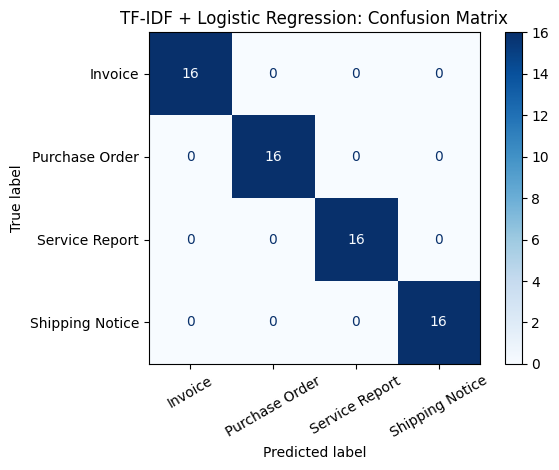

In [6]:
# TF-IDF converts text into numerical features
# Logistic Regression learns document category patterns

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Train the classifier
lr_pipeline.fit(X_train, y_train)

# Predict unseen-template documents
y_pred_lr = lr_pipeline.predict(X_test)

# Evaluate performance
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    zero_division=0
))

# Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    cmap="Blues",
    xticks_rotation=30
)

plt.title("TF-IDF + Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

## Logistic Regression results

- Accuracy: 100%
- Macro-F1: 1
- Correct predictions: 64/64

All 16 test documents in each category were classified correctly.

- Is this good? Technically, yes. But scientifically, we should investigate why the performance is perfect.

- The synthetic documents contain obvious category-specific words such as "invoice," "purchase order," "shipment," and "service report."

- Even though we separated the templates, the model could be relying on those keywords rather than understanding more realistic business language.

Before moving on, I want to perform a small robustness experiment.

## Step 6 - Test whether the classifier relies on obvious keywords

The initial classifier achieved perfect accuracy on the
synthetic test dataset.

However, category-specific terminology may make the
classification task artificially easy.

To investigate this limitation, this experiment removes
explicit document-type keywords from the test documents
and measures the change in classification performance.

In [7]:
import re
from sklearn.metrics import f1_score

# Remove obvious document-category identifiers
keywords = [
    "invoice",
    "billing statement",
    "purchase order",
    "procurement request",
    "order authorization",
    "shipment",
    "delivery notification",
    "logistics update",
    "service report",
    "maintenance record",
    "technical service summary"
]

def remove_keywords(text):
    cleaned = text

    for keyword in sorted(keywords, key=len, reverse=True):
        cleaned = re.sub(
            re.escape(keyword),
            "",
            cleaned,
            flags=re.IGNORECASE
        )

    return re.sub(r"\s+", " ", cleaned).strip()

# Create modified test documents
X_test_robust = X_test.apply(remove_keywords)

# Predict using the original trained model
y_pred_robust = lr_pipeline.predict(X_test_robust)

# Compare performance
original_f1 = f1_score(
    y_test, y_pred_lr, average="macro"
)

robust_f1 = f1_score(
    y_test, y_pred_robust, average="macro"
)

print("Original Macro F1:", round(original_f1, 4))
print("Keyword-Removed Macro F1:", round(robust_f1, 4))

print("\nPerformance difference:",
      round(original_f1 - robust_f1, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_robust,
    zero_division=0
))

# Show examples
comparison = pd.DataFrame({
    "Original Text": X_test.values,
    "Modified Text": X_test_robust.values,
    "Actual Category": y_test.values,
    "Predicted Category": y_pred_robust
})

display(comparison.head(8))

Original Macro F1: 1.0
Keyword-Removed Macro F1: 1.0

Performance difference: 0.0

Classification Report:
                 precision    recall  f1-score   support

        Invoice       1.00      1.00      1.00        16
 Purchase Order       1.00      1.00      1.00        16
 Service Report       1.00      1.00      1.00        16
Shipping Notice       1.00      1.00      1.00        16

       accuracy                           1.00        64
      macro avg       1.00      1.00      1.00        64
   weighted avg       1.00      1.00      1.00        64



,Original Text,Modified Text,Actual Category,Predicted Category
0,Account Cole LLC received invoice reference DO...,Account Cole LLC received reference DOC-08386....,Invoice,Invoice
1,Account Ray-Bush received invoice reference DO...,Account Ray-Bush received reference DOC-61849....,Invoice,Invoice
2,Account Underwood LLC received invoice referen...,Account Underwood LLC received reference DOC-4...,Invoice,Invoice
3,Account Hernandez and Sons received invoice re...,Account Hernandez and Sons received reference ...,Invoice,Invoice
4,"Account Evans, Fowler and Lynch received invoi...","Account Evans, Fowler and Lynch received refer...",Invoice,Invoice
5,Account Baker PLC received invoice reference D...,Account Baker PLC received reference DOC-82278...,Invoice,Invoice
6,"Account Young, Caldwell and Lewis received inv...","Account Young, Caldwell and Lewis received ref...",Invoice,Invoice
7,Account Taylor-White received invoice referenc...,Account Taylor-White received reference DOC-13...,Invoice,Invoice



### Results and Observations

The Logistic Regression classifier achieved 100% accuracy and a macro F1-score of 1.00, correctly classifying all 64 test documents. To investigate whether the model relied heavily on obvious document-type keywords, we conducted a robustness test by removing terms such as "invoice," "purchase order," "shipment," and "service report" from the test documents. Even after removing these keywords, the classifier maintained 100% accuracy and a macro F1-score of 1.00.

This suggests that the model can still distinguish document categories using other textual patterns, including payment information, order quantities, delivery details, and maintenance-related terminology. However, our dataset was generated using only three templates per category, resulting in repetitive sentence structures and limited linguistic diversity. Additionally, some vocabulary remains strongly associated with individual categories, making the classification task relatively easy.

Although the initial results are promising, perfect accuracy on a small synthetic dataset does not establish reliable performance on real-world business documents. The current experiment also provides limited evidence about how the classifier would handle overlapping terminology, missing information, inconsistent formatting, or unfamiliar writing styles.

**Key Takeaway:** Our initial model demonstrates that TF-IDF and Logistic Regression can successfully classify the current synthetic documents, but the evaluation dataset is not sufficiently challenging to assess generalization. Before comparing additional classification algorithms, we will expand the document templates, introduce overlapping vocabulary and realistic text variations, establish baseline classifiers, and implement template-based cross-validation and more rigorous robustness testing.

## Step 7 - Dataset Improvement and Experimental Redesign

### Objective

The initial classification experiments achieved perfect accuracy
on a small synthetic dataset. However, the documents contained
repetitive sentence structures and category-specific terminology.

To address these limitations, we will develop an expanded dataset
with six templates per document category, overlapping vocabulary,
and varied descriptions of operational issues.

The revised dataset will include:
- Six distinct writing templates per document category
- Shared terminology across document categories
- Free-text notes describing delays, damage, and payment issues
- Variations in sentence structure and wording
- Missing or incomplete information in selected documents

The objective is to create a more challenging classification
problem and evaluate how well NLP models generalize to
previously unseen document templates.

The original dataset and results will be preserved as
the initial baseline experiment.


In [16]:
# Revised Step 7: Expanded Synthetic Dataset
import random
import pandas as pd
from faker import Faker

# --------------------------------------------------
# 1. Reproducibility
# --------------------------------------------------

SEED = 42
rng = random.Random(SEED)

fake_v2 = Faker()
fake_v2.seed_instance(SEED)

# Preserve original 200-document experiment
df_original = df.copy()


# --------------------------------------------------
# 2. Six writing templates per document category
# --------------------------------------------------

expanded_templates = {

    "Invoice": [
        "Billing reference {id}. {company} owes ${amount} for completed work.",

        "Payment of ${amount} remains outstanding for {company}. Record {id}.",

        "A financial statement was prepared for {company} on {date}. Balance: ${amount}.",

        "Customer {company} requested clarification about charges totaling ${amount}.",

        "The accounts team recorded ${amount} against reference {id} for {company}.",

        "Services provided to {company} resulted in an amount payable of ${amount}."
    ],

    "Purchase Order": [
        "{company} requested {qty} units under purchasing reference {id}.",

        "The procurement team approved an acquisition valued at ${amount} for {company}.",

        "Materials totaling {qty} units were requested for delivery to {company}.",

        "Supply request {id} specifies {qty} items and an expected arrival date.",

        "A purchasing authorization was issued for {company} with a value of ${amount}.",

        "The operations department requested additional equipment from {company}."
    ],

    "Shipping Notice": [
        "The goods assigned to {company} left the distribution center on {date}.",

        "Transport reference {id} confirms that {qty} units are in transit.",

        "A delivery update indicates that the consignment for {company} is delayed.",

        "The warehouse released {qty} packages for distribution to {company}.",

        "The logistics department updated the expected arrival date for {company}.",

        "A carrier notification confirms dispatch under tracking reference {id}."
    ],

    "Service Report": [
        "A technician inspected equipment at {company} and documented the findings.",

        "Maintenance activities at {company} included component replacement.",

        "The technical team completed diagnostic testing under reference {id}.",

        "An equipment malfunction was investigated at the {company} facility.",

        # Corrected template 4
        "A repair visit was completed at {company} on {date}. "
        "The technician inspected equipment, reviewed charges, "
        "and recorded service reference {id}.",

        # Corrected template 5
        "A field engineer investigated operational issues at "
        "{company} under reference {id}. "
        "Corrective actions were recommended following inspection."
    ]
}


# --------------------------------------------------
# 3. Operational notes shared across categories
# --------------------------------------------------

issue_notes = {

    "delay": [
        "Additional note: processing was postponed due to unavailable stock.",

        "Additional note: the scheduled activity could not be completed on time.",

        "Additional note: an unexpected delay requires follow-up."
    ],

    "damage": [
        "Additional note: several items were reported damaged.",

        "Additional note: physical defects were identified during inspection.",

        "Additional note: the received materials require condition verification."
    ],

    "payment": [
        "Additional note: a payment discrepancy is under review.",

        "Additional note: the customer requested a billing adjustment.",

        "Additional note: financial approval is still pending."
    ]
}


# --------------------------------------------------
# 4. Generate 600 synthetic business documents
# --------------------------------------------------

records_v2 = []

for category, template_list in expanded_templates.items():

    for template_id, template in enumerate(template_list):

        for _ in range(25):

            values = {
                "id": fake_v2.bothify(text="REF-#####"),
                "company": fake_v2.company(),
                "amount": round(
                    rng.uniform(100, 10000), 2
                ),
                "qty": rng.randint(1, 500),
                "date": str(fake_v2.date_this_year())
            }

            # Generate document text
            text = template.format(**values)

            # Select a shared operational issue
            issue_type = rng.choice(
                list(issue_notes.keys())
            )

            note = rng.choice(issue_notes[issue_type])

            # Include notes in approximately 80% of documents
            has_note = rng.random() < 0.80

            if has_note:
                text += " " + note

            # Introduce incomplete information
            if rng.random() < 0.15:
                text += (
                    " Some supporting details are unavailable."
                )

            # Store document information
            records_v2.append({
                "document_id": f"NEW-{len(records_v2)+1:04d}",
                "category": category,
                "text": text,
                "template_id": template_id,
                "issue_type": issue_type if has_note else "none"
            })


# --------------------------------------------------
# 5. Convert records into a Pandas DataFrame
# --------------------------------------------------

df_v2 = pd.DataFrame(records_v2)


# --------------------------------------------------
# 6. Dataset quality checks
# --------------------------------------------------

print("Expanded dataset shape:", df_v2.shape)

print("\nDocuments per category:")
print(df_v2["category"].value_counts())

print("\nTemplates per category:")
display(
    pd.crosstab(
        df_v2["category"],
        df_v2["template_id"]
    )
)

print("\nMissing values:")
print(df_v2.isnull().sum())

print("\nDuplicate document texts:")
print(df_v2["text"].duplicated().sum())


# --------------------------------------------------
# 7. Validate dataset automatically
# --------------------------------------------------

assert len(df_v2) == 600, "Dataset should contain 600 documents."

assert df_v2["category"].nunique() == 4, \
    "Dataset should contain 4 categories."

assert (df_v2["category"].value_counts() == 150).all(), \
    "Each category should contain 150 documents."

assert (
    pd.crosstab(
        df_v2["category"],
        df_v2["template_id"]
    ) == 25
).all().all(), \
    "Each category-template combination should contain 25 documents."

assert df_v2.isnull().sum().sum() == 0, \
    "Dataset contains missing values."

assert df_v2["text"].duplicated().sum() == 0, \
    "Dataset contains duplicate texts."

print("\nAll dataset validation checks passed!")


# --------------------------------------------------
# 8. Display sample documents
# --------------------------------------------------

display(df_v2.head(10))

Expanded dataset shape: (600, 5)

Documents per category:
category
Invoice            150
Purchase Order     150
Shipping Notice    150
Service Report     150
Name: count, dtype: int64

Templates per category:


template_id,0,1,2,3,4,5
category,,,,,,
Invoice,25,25,25,25,25,25
Purchase Order,25,25,25,25,25,25
Service Report,25,25,25,25,25,25
Shipping Notice,25,25,25,25,25,25



Missing values:
document_id    0
category       0
text           0
template_id    0
issue_type     0
dtype: int64

Duplicate document texts:
0

All dataset validation checks passed!


,document_id,category,text,template_id,issue_type
0,NEW-0001,Invoice,Billing reference REF-10433. Doyle Ltd owes $6...,0,payment
1,NEW-0002,Invoice,Billing reference REF-81960. Davis and Sons ow...,0,payment
2,NEW-0003,Invoice,Billing reference REF-08386. Cole LLC owes $10...,0,payment
3,NEW-0004,Invoice,Billing reference REF-02654. Lewis LLC owes $6...,0,damage
4,NEW-0005,Invoice,Billing reference REF-61559. Roman-Blair owes ...,0,delay
5,NEW-0006,Invoice,Billing reference REF-61849. Ray-Bush owes $22...,0,damage
6,NEW-0007,Invoice,Billing reference REF-34131. Ramirez-Reid owes...,0,damage
7,NEW-0008,Invoice,"Billing reference REF-55341. Reid, Ferguson an...",0,delay
8,NEW-0009,Invoice,Billing reference REF-48350. Underwood LLC owe...,0,payment
9,NEW-0010,Invoice,"Billing reference REF-13953. Porter, Wilkerson...",0,none


In [17]:
# Inspect duplicate documents
duplicates = df_v2[
    df_v2.duplicated(subset=["text"], keep=False)
].sort_values("text")

print("Rows belonging to duplicate groups:", len(duplicates))

display(
    duplicates[
        ["document_id", "category", "template_id", "text"]
    ].head(12)
)

# Remove repeated text while retaining the first occurrence
df_v2_clean = (
    df_v2.drop_duplicates(subset=["text"])
    .reset_index(drop=True)
)

print("\nOriginal documents:", len(df_v2))
print("Cleaned documents:", len(df_v2_clean))
print("Duplicates remaining:",
      df_v2_clean["text"].duplicated().sum())

print("\nCategory distribution after cleaning:")
print(df_v2_clean["category"].value_counts())

print("\nTemplate distribution after cleaning:")
display(pd.crosstab(
    df_v2_clean["category"],
    df_v2_clean["template_id"]
))

Rows belonging to duplicate groups: 0


,document_id,category,template_id,text



Original documents: 600
Cleaned documents: 600
Duplicates remaining: 0

Category distribution after cleaning:
category
Invoice            150
Purchase Order     150
Shipping Notice    150
Service Report     150
Name: count, dtype: int64

Template distribution after cleaning:


template_id,0,1,2,3,4,5
category,,,,,,
Invoice,25,25,25,25,25,25
Purchase Order,25,25,25,25,25,25
Service Report,25,25,25,25,25,25
Shipping Notice,25,25,25,25,25,25


## Step 8 - Leave-One-Template-Out Cross-Validation

To evaluate model generalization more rigorously, we use
GroupKFold cross-validation with six folds.

Each fold holds out one template ID across all four document
categories while training on the other five template IDs.

The TF-IDF vectorizer is fitted only on the training portion
of each fold to prevent test-data leakage.

We evaluate accuracy and macro F1-score for each fold, then
report the mean and standard deviation across all six folds.

This experiment measures performance on unseen synthetic
templates, not on independently sourced real documents.

In [18]:
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Use validated expanded dataset
X = df_v2["text"]
y = df_v2["category"]
groups = df_v2["template_id"]

# Six folds: hold out one template slot per fold
cv = GroupKFold(n_splits=6)

fold_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(X, y, groups), start=1
):

    # New pipeline for each fold
    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            max_features=5000
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])

    # Train only on training-fold documents
    model.fit(X.iloc[train_idx], y.iloc[train_idx])

    # Predict held-out template documents
    predictions = model.predict(X.iloc[test_idx])

    accuracy = accuracy_score(
        y.iloc[test_idx], predictions
    )

    macro_f1 = f1_score(
        y.iloc[test_idx],
        predictions,
        average="macro"
    )

    fold_results.append({
        "Fold": fold,
        "Held-Out Template": groups.iloc[test_idx].unique()[0],
        "Train Documents": len(train_idx),
        "Test Documents": len(test_idx),
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

cv_results = pd.DataFrame(fold_results)

print("Leave-One-Template-Out Results:")
display(cv_results.round(4))

print("\nMean Accuracy:",
      round(cv_results["Accuracy"].mean(), 4))

print("Accuracy Standard Deviation:",
      round(cv_results["Accuracy"].std(), 4))

print("\nMean Macro F1:",
      round(cv_results["Macro F1"].mean(), 4))

print("Macro F1 Standard Deviation:",
      round(cv_results["Macro F1"].std(), 4))

Leave-One-Template-Out Results:


,Fold,Held-Out Template,Train Documents,Test Documents,Accuracy,Macro F1
0,1,5,500,100,0.32,0.2693
1,2,4,500,100,0.35,0.3266
2,3,3,500,100,0.30,0.3045
3,4,2,500,100,0.36,0.3320
4,5,1,500,100,0.34,0.2584
5,6,0,500,100,0.63,0.5711



Mean Accuracy: 0.3833
Accuracy Standard Deviation: 0.1227

Mean Macro F1: 0.3437
Macro F1 Standard Deviation: 0.1153



### Results and Interpretation

The six-fold leave-one-template-out cross-validation produced a mean accuracy of 38.33% (standard deviation: 12.27 percentage points) and a mean macro F1-score of 0.3437 (standard deviation: 0.1153).

Performance varied considerably across held-out templates, with accuracy ranging from 30% to 63%. This contrasts sharply with the 100% accuracy achieved in our initial experiment using a smaller, more repetitive synthetic dataset.

The results indicate that the classifier is sensitive to changes in document wording and structure. Although TF-IDF and Logistic Regression can identify patterns present in training examples, their performance decreases when evaluated on unfamiliar templates.

This experiment demonstrates that perfect accuracy on a limited synthetic test set can provide an overly optimistic assessment of model generalization.

**Key Takeaway:** The revised evaluation reveals substantial weaknesses in the classifier's ability to generalize across document templates. Before recommending deployment or comparing more advanced models, we need to establish appropriate baseline performance and investigate the types of documents responsible for classification errors.



## Step-9 Baseline Model Evaluation

To determine whether machine learning provides meaningful
improvements over simpler classification strategies, we
evaluate two baseline approaches:

1. Majority-class classifier
2. Keyword-based rule classifier

Both baselines are evaluated using the same six-fold
leave-one-template-out cross-validation strategy.

Accuracy and macro F1-score are compared with the
previous Logistic Regression results.


In [19]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import GroupKFold
import numpy as np
import pandas as pd
import re

# Rule-based classifier
keyword_rules = {
    "Invoice": [
        "billing", "payment", "amount payable",
        "balance", "charges", "accounts"
    ],
    "Purchase Order": [
        "purchase", "procurement", "supply request",
        "acquisition", "requested", "materials"
    ],
    "Shipping Notice": [
        "shipment", "delivery", "transport",
        "warehouse", "logistics", "carrier",
        "dispatch", "transit"
    ],
    "Service Report": [
        "technician", "maintenance", "repair",
        "inspection", "equipment", "diagnostic",
        "engineer", "malfunction"
    ]
}

def rule_based_predict(text):
    text = text.lower()

    scores = {}

    for category, keywords in keyword_rules.items():
        scores[category] = sum(
            bool(re.search(
                r"\b" + re.escape(keyword) + r"\b",
                text
            ))
            for keyword in keywords
        )

    # Fixed fallback for ties or no matching rules
    return max(scores, key=scores.get)


# Evaluate both baselines using the same folds
cv = GroupKFold(n_splits=6)
baseline_results = []

for fold, (train_idx, test_idx) in enumerate(
    cv.split(
        df_v2["text"],
        df_v2["category"],
        df_v2["template_id"]
    ), start=1
):

    X_train_fold = df_v2["text"].iloc[train_idx]
    X_test_fold = df_v2["text"].iloc[test_idx]

    y_train_fold = df_v2["category"].iloc[train_idx]
    y_test_fold = df_v2["category"].iloc[test_idx]

    # Baseline 1: Most frequent class
    dummy = DummyClassifier(strategy="most_frequent")
    dummy.fit(
        np.zeros((len(X_train_fold), 1)),
        y_train_fold
    )

    dummy_predictions = dummy.predict(
        np.zeros((len(X_test_fold), 1))
    )

    # Baseline 2: Hand-written keyword rules
    rule_predictions = [
        rule_based_predict(text)
        for text in X_test_fold
    ]

    for model_name, predictions in [
        ("Majority Class", dummy_predictions),
        ("Rule-Based", rule_predictions)
    ]:

        baseline_results.append({
            "Fold": fold,
            "Model": model_name,
            "Accuracy": accuracy_score(
                y_test_fold, predictions
            ),
            "Macro F1": f1_score(
                y_test_fold,
                predictions,
                average="macro"
            )
        })


baseline_df = pd.DataFrame(baseline_results)

print("Baseline Performance Summary:")

baseline_summary = (
    baseline_df.groupby("Model")
    .agg(
        Mean_Accuracy=("Accuracy", "mean"),
        Std_Accuracy=("Accuracy", "std"),
        Mean_Macro_F1=("Macro F1", "mean")
    )
)

display(baseline_summary.round(4))

# Add Logistic Regression from Step 8
comparison_summary = baseline_summary.reset_index()

comparison_summary = pd.concat([
    comparison_summary,
    pd.DataFrame([{
        "Model": "Logistic Regression",
        "Mean_Accuracy": cv_results["Accuracy"].mean(),
        "Std_Accuracy": cv_results["Accuracy"].std(),
        "Mean_Macro_F1": cv_results["Macro F1"].mean()
    }])
], ignore_index=True)

print("\nOverall Model Comparison:")
display(comparison_summary.round(4))

Baseline Performance Summary:


,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1
Model,,,
Majority Class,0.2500,0.0000,0.1000
Rule-Based,0.8417,0.1127,0.8196



Overall Model Comparison:


,Model,Mean_Accuracy,Std_Accuracy,Mean_Macro_F1
0,Majority Class,0.2500,0.0000,0.1000
1,Rule-Based,0.8417,0.1127,0.8196
2,Logistic Regression,0.3833,0.1227,0.3437


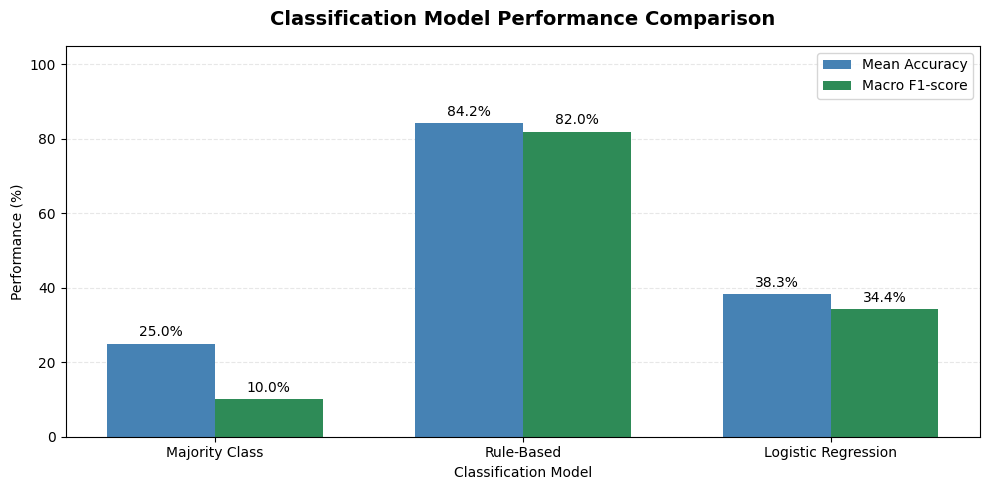

In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Use actual evaluation results from Step 9
plot_df = comparison_summary.copy()

models = plot_df["Model"]
accuracy = plot_df["Mean_Accuracy"] * 100
macro_f1 = plot_df["Mean_Macro_F1"] * 100

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

# Grouped bars
bars1 = ax.bar(
    x - width/2,
    accuracy,
    width,
    label="Mean Accuracy",
    color="steelblue"
)

bars2 = ax.bar(
    x + width/2,
    macro_f1,
    width,
    label="Macro F1-score",
    color="seagreen"
)

# Display values above bars
ax.bar_label(bars1, fmt="%.1f%%", padding=3)
ax.bar_label(bars2, fmt="%.1f%%", padding=3)

# Chart formatting
ax.set_title(
    "Classification Model Performance Comparison",
    fontsize=14,
    fontweight="bold",
    pad=15
)

ax.set_ylabel("Performance (%)")
ax.set_xlabel("Classification Model")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 105)

ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


### Results and Interpretation

The model comparison highlights a significant difference in performance across the three classification approaches. The Majority-Class baseline achieved 25.00% accuracy and a macro F1-score of 0.1000, as expected for our balanced dataset with four document categories. Logistic Regression performed slightly better, achieving 38.33% mean accuracy and a macro F1-score of 0.3437. However, the Rule-Based classifier substantially outperformed both approaches, achieving 84.17% accuracy and a macro F1-score of 0.8196.

The visualization clearly shows that the Rule-Based classifier is currently the strongest approach for our synthetic dataset. Its performance suggests that document categories can often be identified using specific terminology, even when different document types contain overlapping operational information. However, the keyword rules were manually designed with knowledge of our dataset, which may explain their advantage over Logistic Regression.

An important observation is that our initial Logistic Regression model achieved 100% accuracy, but its performance dropped significantly when evaluated using leave-one-template-out cross-validation. This demonstrates how evaluation methodology and dataset diversity can influence model performance and why a single high accuracy score should not be considered sufficient evidence of reliability.

**Key Takeaway:** A more complex machine learning model does not necessarily outperform a simpler rule-based approach. Our results emphasize the importance of establishing baselines, evaluating generalization, and selecting AI techniques based on measurable evidence rather than model complexity. Before making a deployment recommendation, we need to investigate classification errors and evaluate performance on more diverse, independently written documents.

## Step 10 - Classification Error Analysis

### Objective

The previous experiments showed that Logistic Regression
struggles to generalize to unseen document templates.

This section investigates the model's classification errors
using out-of-fold predictions from six-fold
leave-one-template-out cross-validation.

We will examine:
- Which document categories are most frequently confused
- The distribution of correct and incorrect predictions
- Examples of misclassified business documents
- Whether overlapping terminology contributes to errors

Each document will be evaluated using a model that was
not trained on its template, providing a more reliable
assessment than predictions on training data.

Overall Out-of-Fold Accuracy: 0.3833

Classification Report:
                 precision    recall  f1-score   support

        Invoice       0.28      0.46      0.35       150
 Purchase Order       0.22      0.20      0.21       150
 Service Report       0.77      0.71      0.74       150
Shipping Notice       0.33      0.17      0.22       150

       accuracy                           0.38       600
      macro avg       0.40      0.38      0.38       600
   weighted avg       0.40      0.38      0.38       600



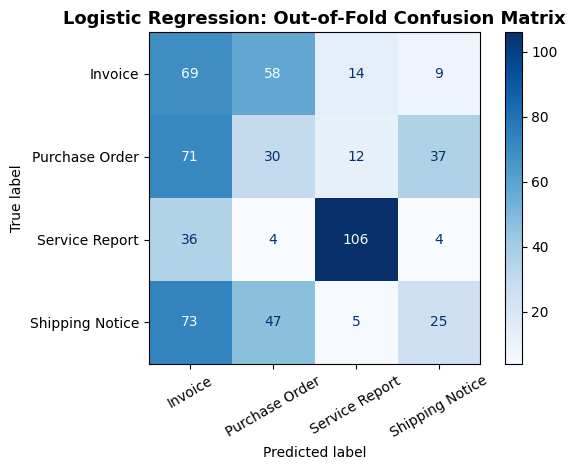

In [22]:
from sklearn.model_selection import GroupKFold
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score
)

import matplotlib.pyplot as plt
import pandas as pd

# Use the revised 600-document dataset
X = df_v2["text"]
y = df_v2["category"]
groups = df_v2["template_id"]

# Six-fold template-based cross-validation
cv = GroupKFold(n_splits=6)

# Logistic Regression pipeline
error_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        ngram_range=(1, 2),
        max_features=5000
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

# Predict every document using a model
# trained without that document's template
oof_predictions = cross_val_predict(
    error_model,
    X,
    y,
    groups=groups,
    cv=cv
)

print("Overall Out-of-Fold Accuracy:",
      round(accuracy_score(y, oof_predictions), 4))

print("\nClassification Report:")
print(classification_report(
    y,
    oof_predictions,
    zero_division=0
))

# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y,
    oof_predictions,
    cmap="Blues",
    xticks_rotation=30
)

plt.title(
    "Logistic Regression: Out-of-Fold Confusion Matrix",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [23]:
# Create error-analysis DataFrame
error_df = df_v2[
    ["document_id", "category", "template_id",
     "issue_type", "text"]
].copy()

error_df["predicted_category"] = oof_predictions

error_df["correct"] = (
    error_df["category"] ==
    error_df["predicted_category"]
)

# Separate incorrect predictions
misclassified = error_df[
    ~error_df["correct"]
].copy()

print("Total documents:", len(error_df))
print("Correct predictions:", error_df["correct"].sum())
print("Incorrect predictions:", len(misclassified))

print("\nMost common classification errors:")

error_pairs = (
    misclassified.groupby(
        ["category", "predicted_category"]
    )
    .size()
    .reset_index(name="count")
    .sort_values("count", ascending=False)
)

display(error_pairs.head(10))

print("\nSample misclassified documents:")
display(
    misclassified[
        ["document_id", "category",
         "predicted_category", "template_id",
         "issue_type", "text"]
    ].head(12)
)

Total documents: 600
Correct predictions: 230
Incorrect predictions: 370

Most common classification errors:


,category,predicted_category,count
9,Shipping Notice,Invoice,73
3,Purchase Order,Invoice,71
0,Invoice,Purchase Order,58
10,Shipping Notice,Purchase Order,47
5,Purchase Order,Shipping Notice,37
6,Service Report,Invoice,36
1,Invoice,Service Report,14
4,Purchase Order,Service Report,12
2,Invoice,Shipping Notice,9
11,Shipping Notice,Service Report,5



Sample misclassified documents:


,document_id,category,predicted_category,template_id,issue_type,text
11,NEW-0012,Invoice,Service Report,0,payment,Billing reference REF-28710. Hernandez and Son...
12,NEW-0013,Invoice,Service Report,0,delay,"Billing reference REF-69166. Ferrell, Rice and..."
14,NEW-0015,Invoice,Service Report,0,delay,"Billing reference REF-48281. Evans, Fowler and..."
17,NEW-0018,Invoice,Service Report,0,payment,Billing reference REF-82278. Baker PLC owes $5...
22,NEW-0023,Invoice,Service Report,0,delay,Billing reference REF-66701. Powell LLC owes $...
24,NEW-0025,Invoice,Service Report,0,none,"Billing reference REF-17810. Kidd, Huff and No..."
35,NEW-0036,Invoice,Purchase Order,1,damage,Payment of $801.49 remains outstanding for Rob...
51,NEW-0052,Invoice,Service Report,2,payment,A financial statement was prepared for William...
55,NEW-0056,Invoice,Service Report,2,delay,A financial statement was prepared for Hensley...
58,NEW-0059,Invoice,Service Report,2,delay,A financial statement was prepared for Perry-C...


In [24]:
from google.colab import userdata

# Retrieve GitHub token securely
github_token = userdata.get("GITHUB_TOKEN")

if github_token:
    print("GitHub token successfully loaded!")
else:
    print("GitHub token not found.")

GitHub token successfully loaded!


In [ ]:
from google.colab import drive

drive.mount("/content/drive")